# PCA for preparing use of linear model

In the density data set we have a lot of parameters and before using a linear model we need to reduce the number of parameters. In this notebook we will use PCA to reduce the number of parameters and then use the reduced data set to fit a linear model



In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from narwhals.dependencies import is_pyarrow_chunked_array
from numpy.ma.core import ones

warnings.filterwarnings('ignore')
data = pd.read_csv('data/bodyfat.csv')
df = pd.DataFrame(data)
print(df.shape)
df


(252, 15)


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,1.0736,11.0,70,134.25,67.00,34.9,89.2,83.6,88.8,49.6,34.8,21.5,25.6,25.7,18.5
248,1.0236,33.6,72,201.00,69.75,40.9,108.5,105.0,104.5,59.6,40.8,23.2,35.2,28.6,20.1
249,1.0328,29.3,72,186.75,66.00,38.9,111.1,111.5,101.7,60.3,37.3,21.5,31.3,27.2,18.0
250,1.0399,26.0,72,190.75,70.50,38.9,108.3,101.3,97.8,56.0,41.6,22.7,30.5,29.4,19.8


First step is to make the centered data set
We drop the density column and bodyfat column because that is the data we want to explain and then center the data by subtracting the mean of each column from the values in that column.

Remember to syore mean of each column so that we can use it later to center new data before using the linear model.

In [18]:
X = df.drop(['Density', 'BodyFat'], axis=1)
Mean = X.mean()
X = X - Mean
X

,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,-21.884921,-24.674405,-2.39881,-1.792063,-7.724206,-7.355952,-5.404762,-0.405952,-1.290476,-1.202381,-0.273413,-1.263889,-1.129762
1,-22.884921,-5.674405,2.10119,0.507937,-7.224206,-9.555952,-1.204762,-0.705952,-1.290476,0.297619,-1.773413,0.236111,-0.029762
2,-22.884921,-24.924405,-3.89881,-3.992063,-5.024206,-4.655952,-0.704762,0.194048,0.309524,0.897619,-3.473413,-3.463889,-1.629762
3,-18.884921,5.825595,2.10119,-0.592063,0.975794,-6.155952,1.295238,0.694048,-1.290476,-0.302381,0.126587,0.736111,-0.029762
4,-20.884921,5.325595,1.10119,-3.592063,-3.524206,7.444048,1.995238,3.794048,3.609524,0.897619,-0.073413,-0.963889,-0.529762
...,...,...,...,...,...,...,...,...,...,...,...,...,...
247,25.115079,-44.674405,-3.14881,-3.092063,-11.624206,-8.955952,-11.104762,-9.805952,-3.790476,-1.602381,-6.673413,-2.963889,0.270238
248,27.115079,22.075595,-0.39881,2.907937,7.675794,12.444048,4.595238,0.194048,2.209524,0.097619,2.926587,-0.063889,1.870238
249,27.115079,7.825595,-4.14881,0.907937,10.275794,18.944048,1.795238,0.894048,-1.290476,-1.602381,-0.973413,-1.463889,-0.229762
250,27.115079,11.825595,0.35119,0.907937,7.475794,8.744048,-2.104762,-3.405952,3.009524,-0.402381,-1.773413,0.736111,1.570238


#### Using SVD on X
Next step whe use SVD of the X matrix to get the principal components. The SVD of a matrix X is given by X = U S V^T where U and V are orthogonal matrices and S is a diagonal matrix with the singular values of X on the diagonal. The columns of V are the principal components of X and the singular values in S give us the amount of variance explained by each principal component.

In [19]:
(U, S, Vt) = np.linalg.svd(X, full_matrices=False)
print(S)


[525.89161188 206.60565631  75.55579045  53.35903578  44.73248538
  34.2609981   29.71799855  24.49201637  22.01146901  20.57875179
  18.7248157   16.27066322   7.89728003]


Now we calculate the energy retention such that we can decide how many principal components to keep. The energy retention is given by the sum of the squares of the singular values divided by the sum of the squares of all singular values. We can plot the energy retention as a function of the number of principal components to see how many we need to keep to retain a certain amount of variance in the data.

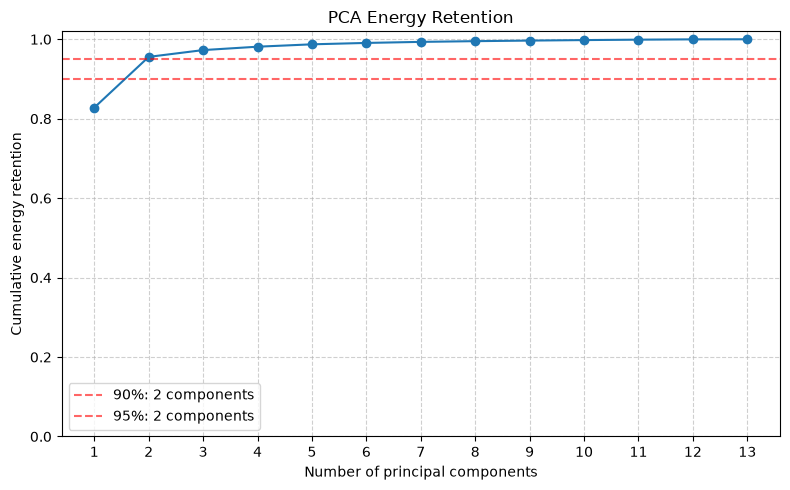

In [20]:
energy = S ** 2
energy_retention = np.cumsum(energy) / np.sum(energy)
components = np.arange(1, len(S) + 1)

plt.figure(figsize=(8, 5))
plt.plot(components, energy_retention, marker='o')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative energy retention')
plt.title('PCA Energy Retention')
plt.xticks(components)
plt.ylim(0, 1.02)
plt.grid(True, linestyle='--', alpha=0.6)

for threshold in (0.90, 0.95):
    n_components = np.argmax(energy_retention >= threshold) + 1
    plt.axhline(threshold, color='red', linestyle='--', alpha=0.6,
                label=f'{threshold:.0%}: {n_components} components')

plt.legend()
plt.tight_layout()
plt.show()


From the plot we can see that we need to keep 2 principal components to retain 95% of the variance in the data.

In [59]:
retained=3
U_pca = U[:, :retained]
vt_pca = Vt[:retained, :]
S_pca = np.diag(S[:retained])
print(U_pca.shape, S_pca.shape, vt_pca.shape)

(252, 3) (3, 3) (3, 13)


The reduced data set is given by the product of U_pca and S_pca. This gives us a new data set with 2 principal components that we can use to fit a linear model.

(252, 13)
[[-2.74782469e+01 -2.10804259e+01  6.15128189e+00 ...  1.69883104e-02
  -9.48220584e-01 -1.47636309e-02]
 [-1.01277653e+01 -2.43146341e+01 -3.03287150e+00 ...  1.06424939e+00
   1.82579130e-01 -1.39526336e-01]
 [-2.55765759e+01 -2.13042612e+01  1.07716712e+01 ...  6.36935358e-01
  -1.17265771e+00  1.90512850e-01]
 ...
 [ 1.52743871e+01  3.06381389e+01  9.88153441e+00 ... -7.98597606e-02
   1.05180168e+00  8.96181402e-02]
 [ 1.42379050e+01  2.81758705e+01 -2.94110370e+00 ... -1.91383236e+00
  -1.64155906e+00 -8.16072639e-01]
 [ 3.49709059e+01  3.00322891e+01 -1.03482450e+00 ...  4.80127118e-01
  -1.31240788e+00 -1.23964027e+00]]


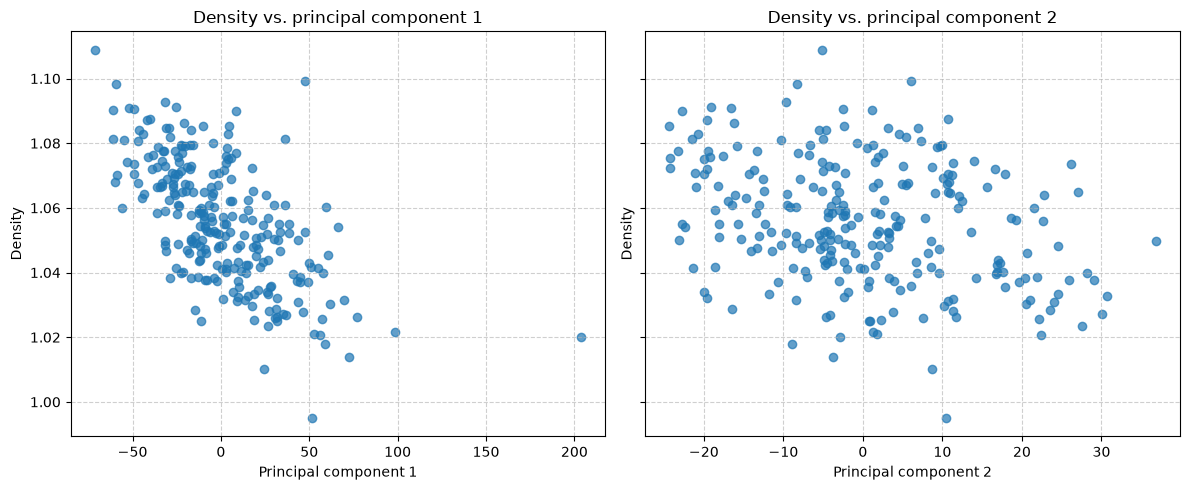

In [37]:
reduced=U_pca @ S_pca
print(reduced.shape)
print(reduced)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for i, ax in enumerate(axes):
    ax.scatter(reduced[:, i], df['Density'], alpha=0.7)
    ax.set_xlabel(f'Principal component {i + 1}')
    ax.set_ylabel('Density')
    ax.set_title(f'Density vs. principal component {i + 1}')
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


The first scatter plot suggests a linear relationship between the first principal component and density, while the second scatter plot does not show a clear linear relationship. Therefore, we first try with two linear dependencies.

In [60]:
reduced=U_pca @ S_pca
D=np.column_stack((np.ones(reduced.shape[0]), reduced))
beta=np.linalg.inv(D.T@D)@D.T@df['Density']
print(beta)
S_res=np.linalg.norm(D@beta-df['Density'])**2
s_tot=np.linalg.norm(df['Density']-df['Density'].mean())**2
R2=1-S_res/s_tot
print(f"R^2: {R2:.4f}")




[ 1.05557381e+00 -3.61394755e-04 -4.42050317e-04 -1.67827792e-03]
R^2: 0.6659


We could also try to model using original data

In [34]:
D_full=np.column_stack((np.ones(df.shape[0]), df.drop(['Density', 'BodyFat'], axis=1)))
beta_full=np.linalg.inv(D_full.T@D_full)@D_full.T@df['Density']
S_res_full=np.linalg.norm(D_full@beta_full-df['Density'])**2
s_tot_full=np.linalg.norm(df['Density']-df['Density'].mean())**2
R2_full=1-S_res_full/s_tot_full
print(f"R^2 with full data: {R2_full:.4f}")

R^2 with full data: 0.7381


From this we can see that the R^2 value is higher when using the full data set compared to using the reduced data set with PCA. This suggests that while PCA can help reduce dimensionality, it may also lead to a loss of information that is important for predicting density. Therefore, it is important to carefully consider the trade-offs between dimensionality reduction and model performance when using PCA in practice.

If we assume the current model and measure new data we should reconstruct the predicted density by the following procedure
1. Center the new data by subtracting the mean of each column from the values in that column.
2. Project the centered data onto the principal components by multiplying the centered data by $V_{pca}$
3. Use the linear model coefficients (beta) to predict the density by multiplying the projected data by the coefficients and adding the intercept term.

So lets assume that the first line of data is a new measurement


In [62]:
newData=df.drop(['Density', 'BodyFat'], axis=1).iloc[0, :].values
transformed=(newData-Mean) @ vt_pca.T
transformed=np.insert(transformed, 0, 1)
print(beta)
print(transformed)
print(beta.shape)
prediction=np.dot(transformed,beta)
print(prediction)

[ 1.05557381e+00 -3.61394755e-04 -4.42050317e-04 -1.67827792e-03]
[  1.         -27.47824692 -21.08042587   6.15128189]
(4,)
1.064499352183227


Try to experiment with this data set and see if you can find a better model. You can try to use different number of principal components or try to use different linear models. You can also try to use different data sets and see if you can find a better model.